In [4]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchsummary import summary

In [5]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
                                                                                                                     

In [6]:
from sklearn import datasets
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, accuracy_score, f1_score, ConfusionMatrixDisplay, confusion_matrix

In [32]:
RANDOM_STATE = 24 # REMEMBER: to remove at the time of promotion to production
np.random.seed(seed=RANDOM_STATE)

EPOCHS = 200 # number of epochs
ALPHA = 0.001 # learning rate
TEST_SIZE = 0.2

# parameters for Matplotlib
params = {'legend.fontsize': 'medium',
          'figure.figsize': (15, 10),
          'axes.labelsize': 'medium',
          'axes.titlesize': 'medium',
          'xtick.labelsize': 'medium',
          'ytick.labelsize': 'medium'
         }

plt.rcParams.update(params)
CMAP = plt.cm.coolwarm

In [33]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using {torch.cuda.get_device_name(0) if device.type == 'cuda' else 'cpu'}")

Using cpu


In [34]:
folder = Path(r"c:\amit-smit\DL")
file_path = folder / 'DNN INPUT' / 'machine_learning' / 'wine.csv'

path_string = str(file_path)    # a normal string
print(path_string)

data_df = pd.read_csv(path_string, header=None)
data_df.head()

c:\amit-smit\DL\DNN INPUT\machine_learning\wine.csv


,0,1,2,3,4,5,6,7,8,9,10,11,12,13
0,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065,1
1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050,1
2,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185,1
3,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480,1
4,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735,1


In [35]:
x,y = data_df.drop(13, axis=1).to_numpy(), data_df[13].to_numpy()

In [36]:
x_train, x_test, y_train, y_test = train_test_split(x,y,random_state=RANDOM_STATE,test_size=0.2)

In [37]:
sc = StandardScaler()
x_train = sc.fit_transform(x_train)
x_test = sc.transform(x_test)

In [38]:
class FitDataset(Dataset):
    def __init__(self,x,y):
        self.x = torch.tensor(x, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)

    def __len__(self):
        return len(self.x)
    def __getitem__(self, idx):
        return self.x[idx], self.y[idx]

In [39]:
train_dataset = FitDataset(x_train, y_train)
train_loader = DataLoader(dataset=train_dataset, batch_size=32, shuffle=True)

In [40]:
for b_idx, (data, target) in enumerate(train_loader):
    print(f'Batch {b_idx}: '
          f'Data: {data.shape}'
          f'Labels: {target.shape}')

Batch 0: Data: torch.Size([32, 13])Labels: torch.Size([32])
Batch 1: Data: torch.Size([32, 13])Labels: torch.Size([32])
Batch 2: Data: torch.Size([32, 13])Labels: torch.Size([32])
Batch 3: Data: torch.Size([32, 13])Labels: torch.Size([32])
Batch 4: Data: torch.Size([14, 13])Labels: torch.Size([14])


In [41]:
test_dataset = FitDataset(x_test, y_test)
test_loader = DataLoader(dataset=test_dataset)

### Model using Module

In [42]:
class Model(nn.Module):
    def __init__(self, input_dim):
        super(Model,self).__init__()
        self.layer1 = nn.Linear(input_dim, 18)
        self.actuv1 = nn.SiLU()
        self.layer2 = nn.Linear(18,4)

    def forward(self, x):
        x = self.layer1(x)
        x = self.actuv1(x)
        x = self.layer2(x)
        return x

In [43]:
model = Model(input_dim=x_train.shape[1]).to(device=device)

In [44]:
list(model.parameters())

[Parameter containing:
 tensor([[-0.1607, -0.1528,  0.0268, -0.0233, -0.0503,  0.2513, -0.0161,  0.2613,
          -0.1227, -0.2656,  0.1975, -0.1058, -0.0903],
         [-0.2309,  0.2381, -0.1140,  0.1761,  0.2506, -0.0170,  0.1509,  0.0767,
           0.1619, -0.0239, -0.2644,  0.1007, -0.1526],
         [ 0.2531, -0.0027, -0.1617,  0.0032,  0.1260, -0.1571, -0.0746, -0.0374,
          -0.0492,  0.2205, -0.1638, -0.1265,  0.0092],
         [ 0.2252,  0.2307,  0.0334,  0.0286, -0.2759, -0.1887, -0.1633,  0.0017,
           0.2515,  0.1203,  0.0969,  0.1667, -0.1786],
         [-0.0864,  0.2229,  0.2558,  0.2158, -0.1687, -0.0528,  0.1532,  0.0723,
           0.1758, -0.2071, -0.0084,  0.0892, -0.0706],
         [-0.0954, -0.0531,  0.0155, -0.1611, -0.0358,  0.0552, -0.2167, -0.0787,
           0.0299, -0.1081, -0.0655,  0.0920,  0.1532],
         [-0.0903,  0.2368, -0.0973,  0.1422,  0.0843,  0.1952,  0.0170,  0.0910,
          -0.1369,  0.1061, -0.0395,  0.0950, -0.0706],
         [-

In [45]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(),
                             lr=ALPHA)
loss, tloss, acc, tacc, n_epoch = [], [], [], [], []

for epoch in range(EPOCHS):
    model.train()
    epoch_loss = 0
    epoch_acc = 0
    tepoch_loss = 0
    tepoch_acc = 0
    for batch_idx, (train_X, train_y) in enumerate(train_loader):
    
        train_X, train_y = train_X.to(device), train_y.to(device)
        predict_prob = model(train_X) # Forward propagation
        batch_loss = loss_fn(predict_prob, train_y) # calculate loss
        epoch_loss += (batch_loss - epoch_loss) / (batch_idx+1)
    
        # Back propagation
        optimizer.zero_grad() # reset
        batch_loss.backward() # back Prop (dWs dbs)
        optimizer.step() # W = W + alpha * dW
    
        _, y_pred = torch.max(predict_prob, 1)
        batch_acc = accuracy_score(train_y.cpu().numpy(), y_pred.data.cpu())
        epoch_acc += (batch_acc - epoch_acc) / (batch_idx+1)

    loss.append(epoch_loss.item())
    acc.append(epoch_acc)

    model.eval()
    with torch.inference_mode():
            for batch_idx, (test_X, test_y) in enumerate(test_loader):
                test_X, test_y = test_X.to(device), test_y.to(device)
                predict_prob_tst = model(test_X) # Forward propagation
                tbatch_loss = loss_fn(predict_prob_tst, test_y) # calculate loss
                tepoch_loss += (tbatch_loss - tepoch_loss) / (batch_idx+1)
                _, y_pred = torch.max(predict_prob_tst, 1)
                tbatch_acc = accuracy_score(test_y.cpu().numpy(), y_pred.data.cpu())
                tepoch_acc += (tbatch_acc - tepoch_acc) / (batch_idx+1)
            tloss.append(tepoch_loss.item())
            tacc.append(tepoch_acc)

    if epoch % 10 == 0:
      print(f'at epoch - {epoch:4d} : loss- {epoch_loss.item():.4f}'
            f' Test Loss - {tepoch_loss.item():.4f}'
             f' Train acc - {epoch_acc:.4f}'
            f' test acc - {tepoch_acc:.4f}')
    

at epoch -    0 : loss- 1.3184 Test Loss - 1.2646 Train acc - 0.3491 test acc - 0.5000


at epoch -   10 : loss- 0.9497 Test Loss - 0.8834 Train acc - 0.9437 test acc - 0.9722
at epoch -   20 : loss- 0.5627 Test Loss - 0.4990 Train acc - 0.9750 test acc - 0.9444
at epoch -   30 : loss- 0.3163 Test Loss - 0.2623 Train acc - 0.9938 test acc - 0.9444
at epoch -   40 : loss- 0.1854 Test Loss - 0.1665 Train acc - 0.9857 test acc - 0.9444
at epoch -   50 : loss- 0.1275 Test Loss - 0.1228 Train acc - 0.9938 test acc - 0.9444
at epoch -   60 : loss- 0.0931 Test Loss - 0.1011 Train acc - 0.9857 test acc - 0.9444
at epoch -   70 : loss- 0.0730 Test Loss - 0.0872 Train acc - 1.0000 test acc - 0.9722
at epoch -   80 : loss- 0.0554 Test Loss - 0.0782 Train acc - 1.0000 test acc - 0.9722
at epoch -   90 : loss- 0.0470 Test Loss - 0.0730 Train acc - 1.0000 test acc - 0.9722
at epoch -  100 : loss- 0.0353 Test Loss - 0.0696 Train acc - 1.0000 test acc - 0.9722
at epoch -  110 : loss- 0.0300 Test Loss - 0.0666 Train acc - 1.0000 test acc - 0.9722
at epoch -  120 : loss- 0.0248 Test Loss - 

In [51]:
loss_df = pd.DataFrame(
    {
        'epoch': np.arange(EPOCHS),
        'loss': loss,
        'test_loss':tloss,
        'acc': acc,
        'test_acc': tacc
    }
)

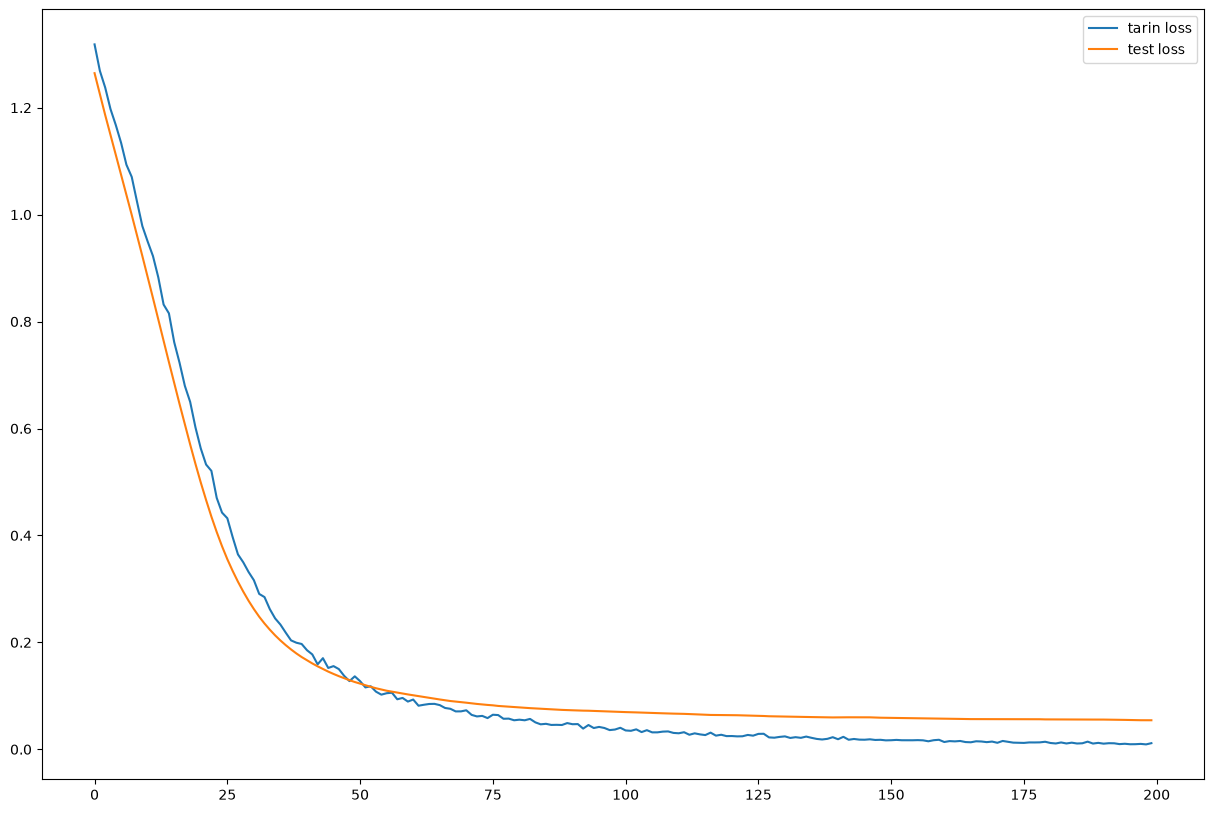

In [54]:
plt.plot(loss_df['epoch'],loss_df['loss'],label='tarin loss')
plt.plot(loss_df['epoch'],loss_df['test_loss'],label='test loss')
plt.legend()
plt.show()

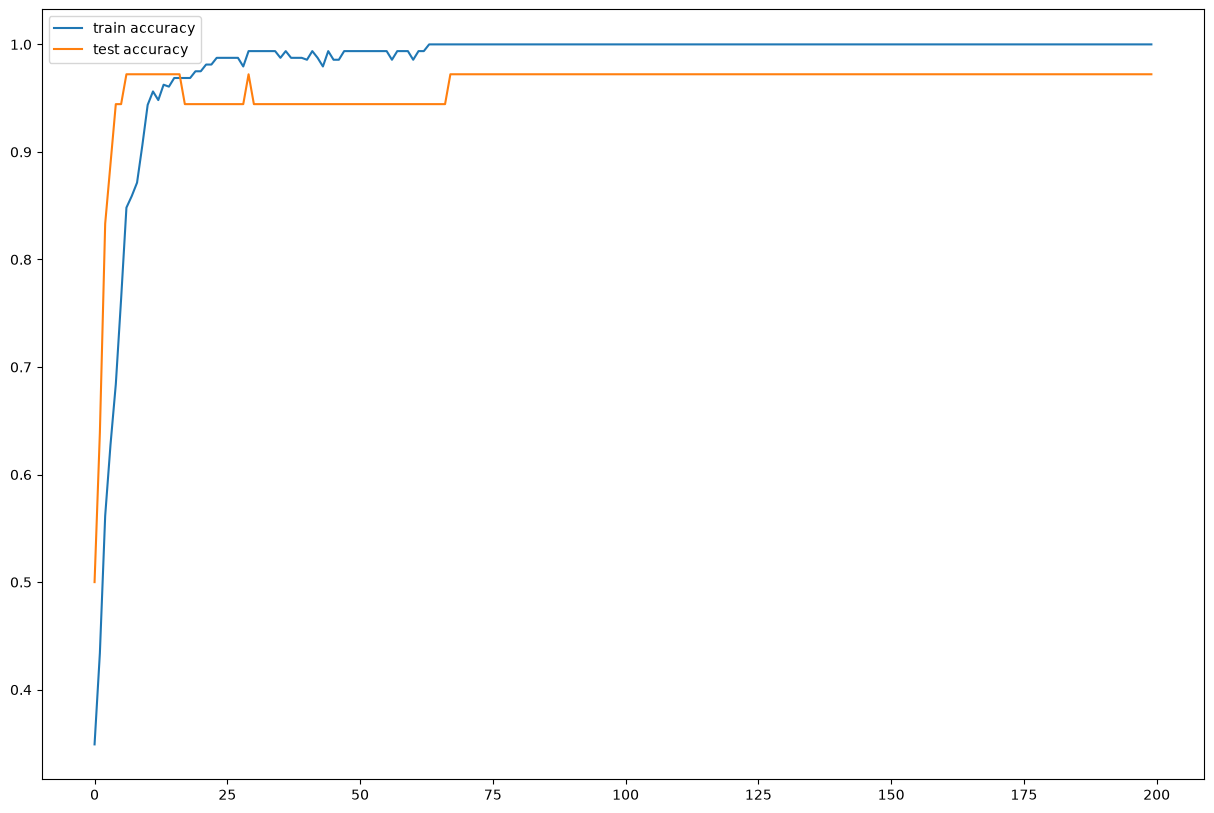

In [55]:
plt.plot(loss_df['epoch'],loss_df['acc'],label='train accuracy')
plt.plot(loss_df['epoch'],loss_df['test_acc'], label='test accuracy')
plt.legend()
plt.show()